In [1]:
#1.1
import pandas as pd

pd.read_csv("C:/Users/santi/OneDrive/Documents/ML/TP1/data/raw/casas_dev.csv").sample(10)


,precio,tipo,Área,metros_cubiertos,unidades,ambientes,pisos,pileta,lat,lon,edad
107,171288.396672,depto,779.742111,758.675218,sqft,5,NaN,False,40.696924,-74.029941,NaN
649,223.386240,casa,230.776200,114.019158,m2,9,3.0,False,-34.681392,-58.287608,16.466252
573,35972.120525,casa,212.322964,136.412716,m2,10,3.0,True,-34.746616,-58.242674,59.663362
822,192812.653058,depto,804.299841,794.061656,sqft,2,NaN,False,40.702811,-73.948855,13.601948
290,125143.436699,depto,875.871792,852.021926,sqft,10,NaN,False,40.670158,-73.976951,9.420901
1069,12671.254612,casa,221.517999,108.031137,m2,10,3.0,False,-34.844037,-58.279814,26.971640
373,127337.540305,depto,687.700834,664.544497,sqft,5,NaN,False,40.835766,-74.004527,13.680816
1500,133179.686965,depto,733.337142,727.331813,sqft,5,NaN,False,40.772688,-73.939282,4.851506
169,5149.902215,depto,71.287870,68.413872,m2,5,NaN,True,-34.707986,-58.266534,NaN
1419,175751.070336,depto,798.828342,774.265596,sqft,5,NaN,False,40.731001,-73.927370,4.163406


1.1
Puedo obvservar que hay muchos datos que tendria que modificar para su analisis, voy a ir nombrando los problemas columna por columna.

Los precios, la mayoria parecen ser consistentes, pero varios tienen precios absurdos, por ejemplo que un departamento vale $0.

El Area y metros cubiertos lo interpreto como el area de la propiedad, y los metros cubiertos por construccion, lo que puede ser interesante ambas columnas como para hacer por ejemplo jardin = area - metros_cubiertos. Tambien puede servir para encontrar errores, si area > metros_cubiertos entonces algo anda mal.

Las unidades habria que unificarlas a m2 o a sqft, ya que el modelo que vayamos a usar va a interpreta las areas como si fueran de la misma unidad.

En pisos, cuando el tipo de propiedad es un depto queda en NaN, tal vez convendria cargarle el valor 0 en ese caso. Y en el caso de las edades tambien, tal vez NaN significa que son propiedades a estrenar, tampoco me gusta que tengan decimales en edad, raro de interpretar.

C:\Users\santi\AppData\Local\Temp\ipykernel_17676\4113988824.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="unidades", loc="upper right")


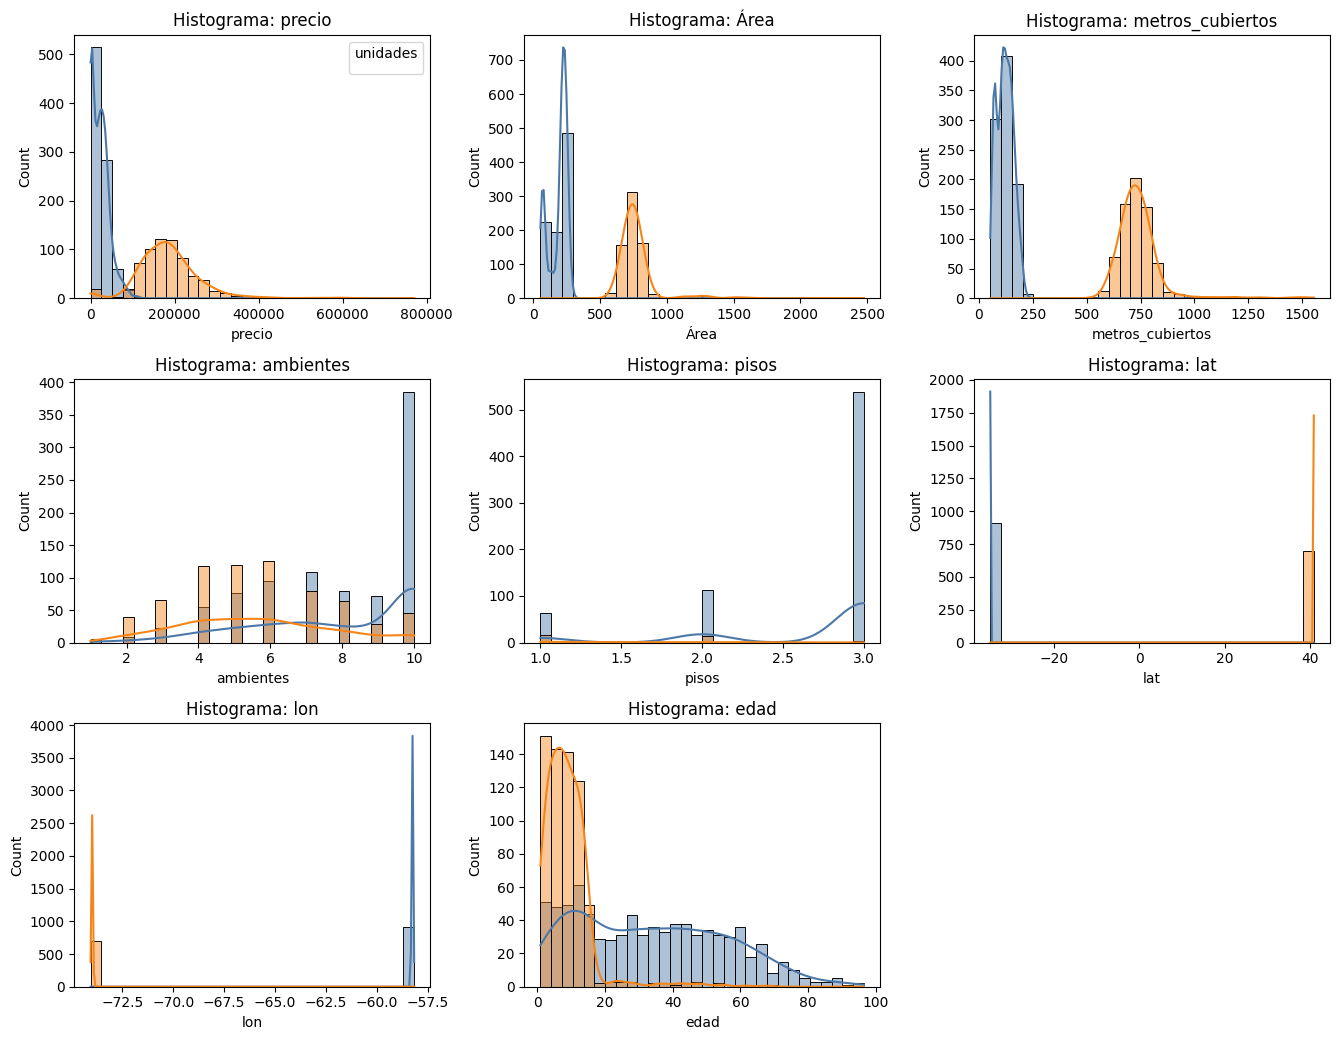

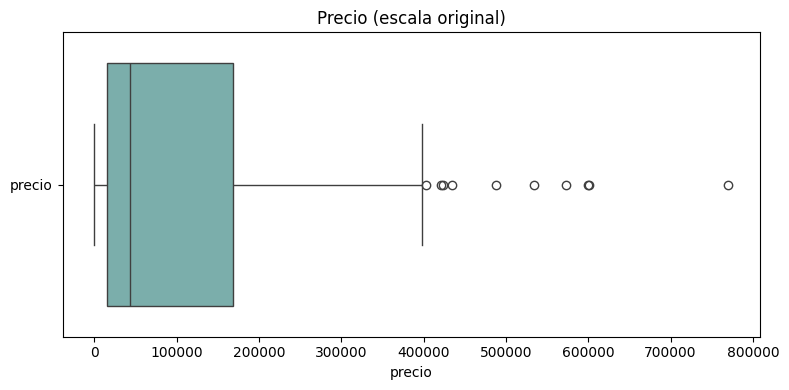

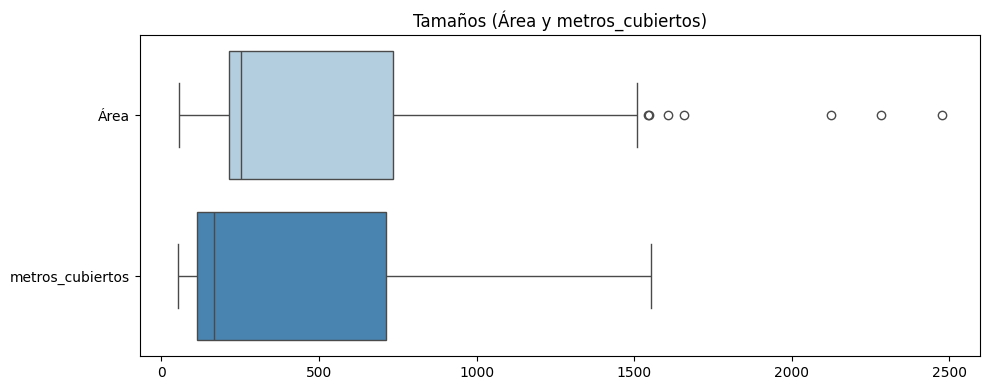

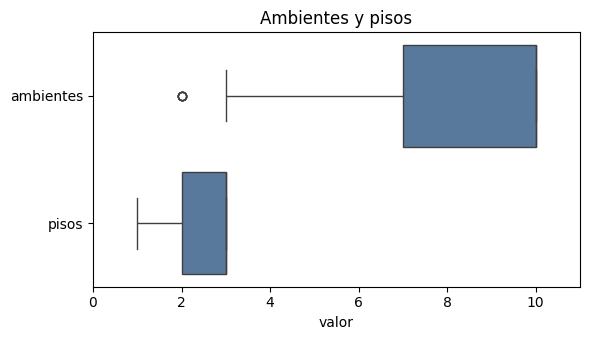

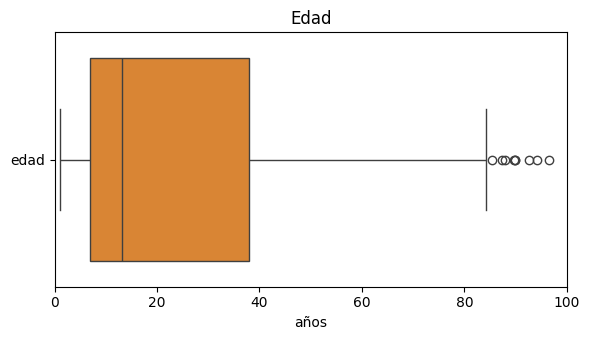

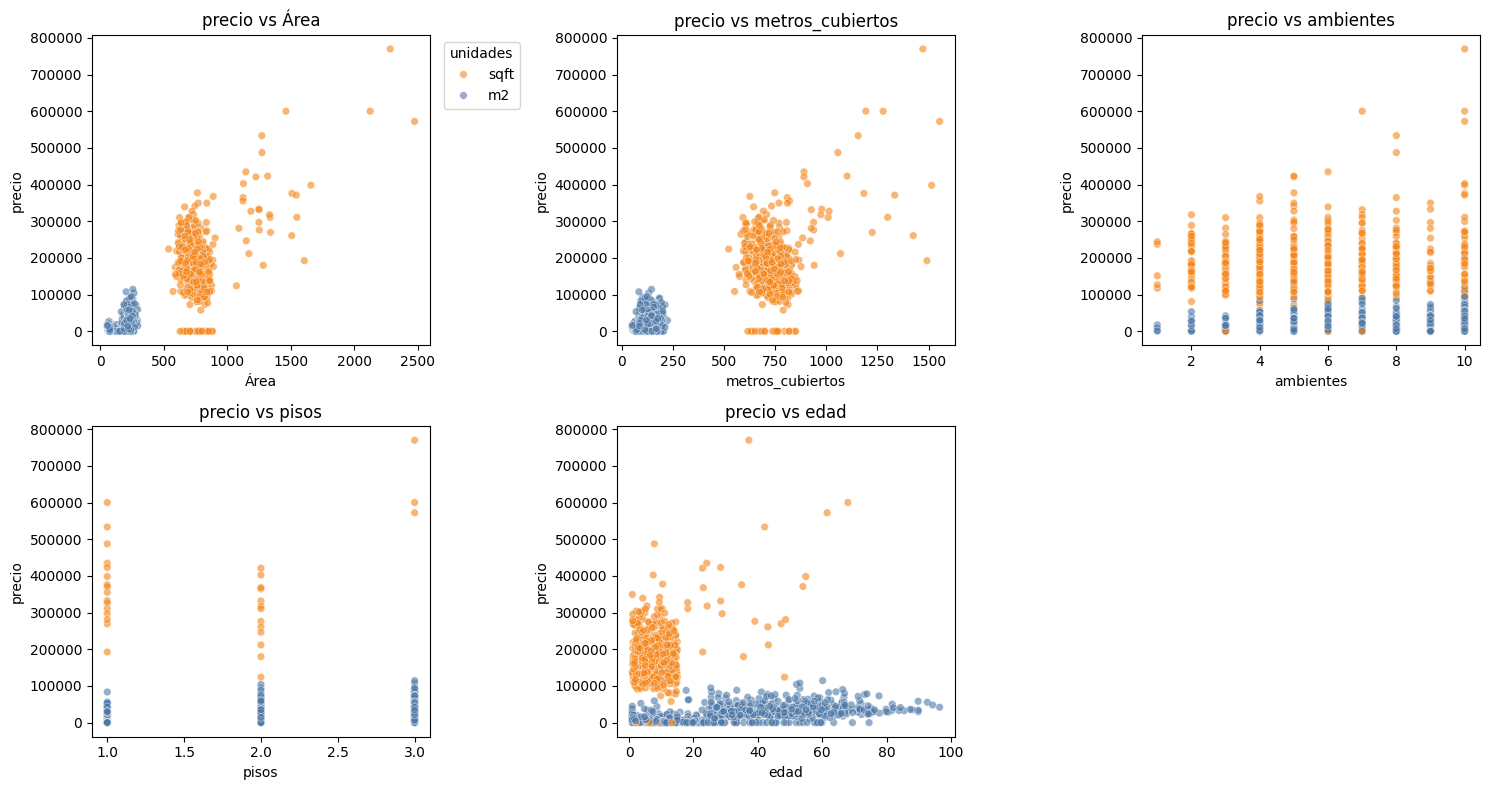

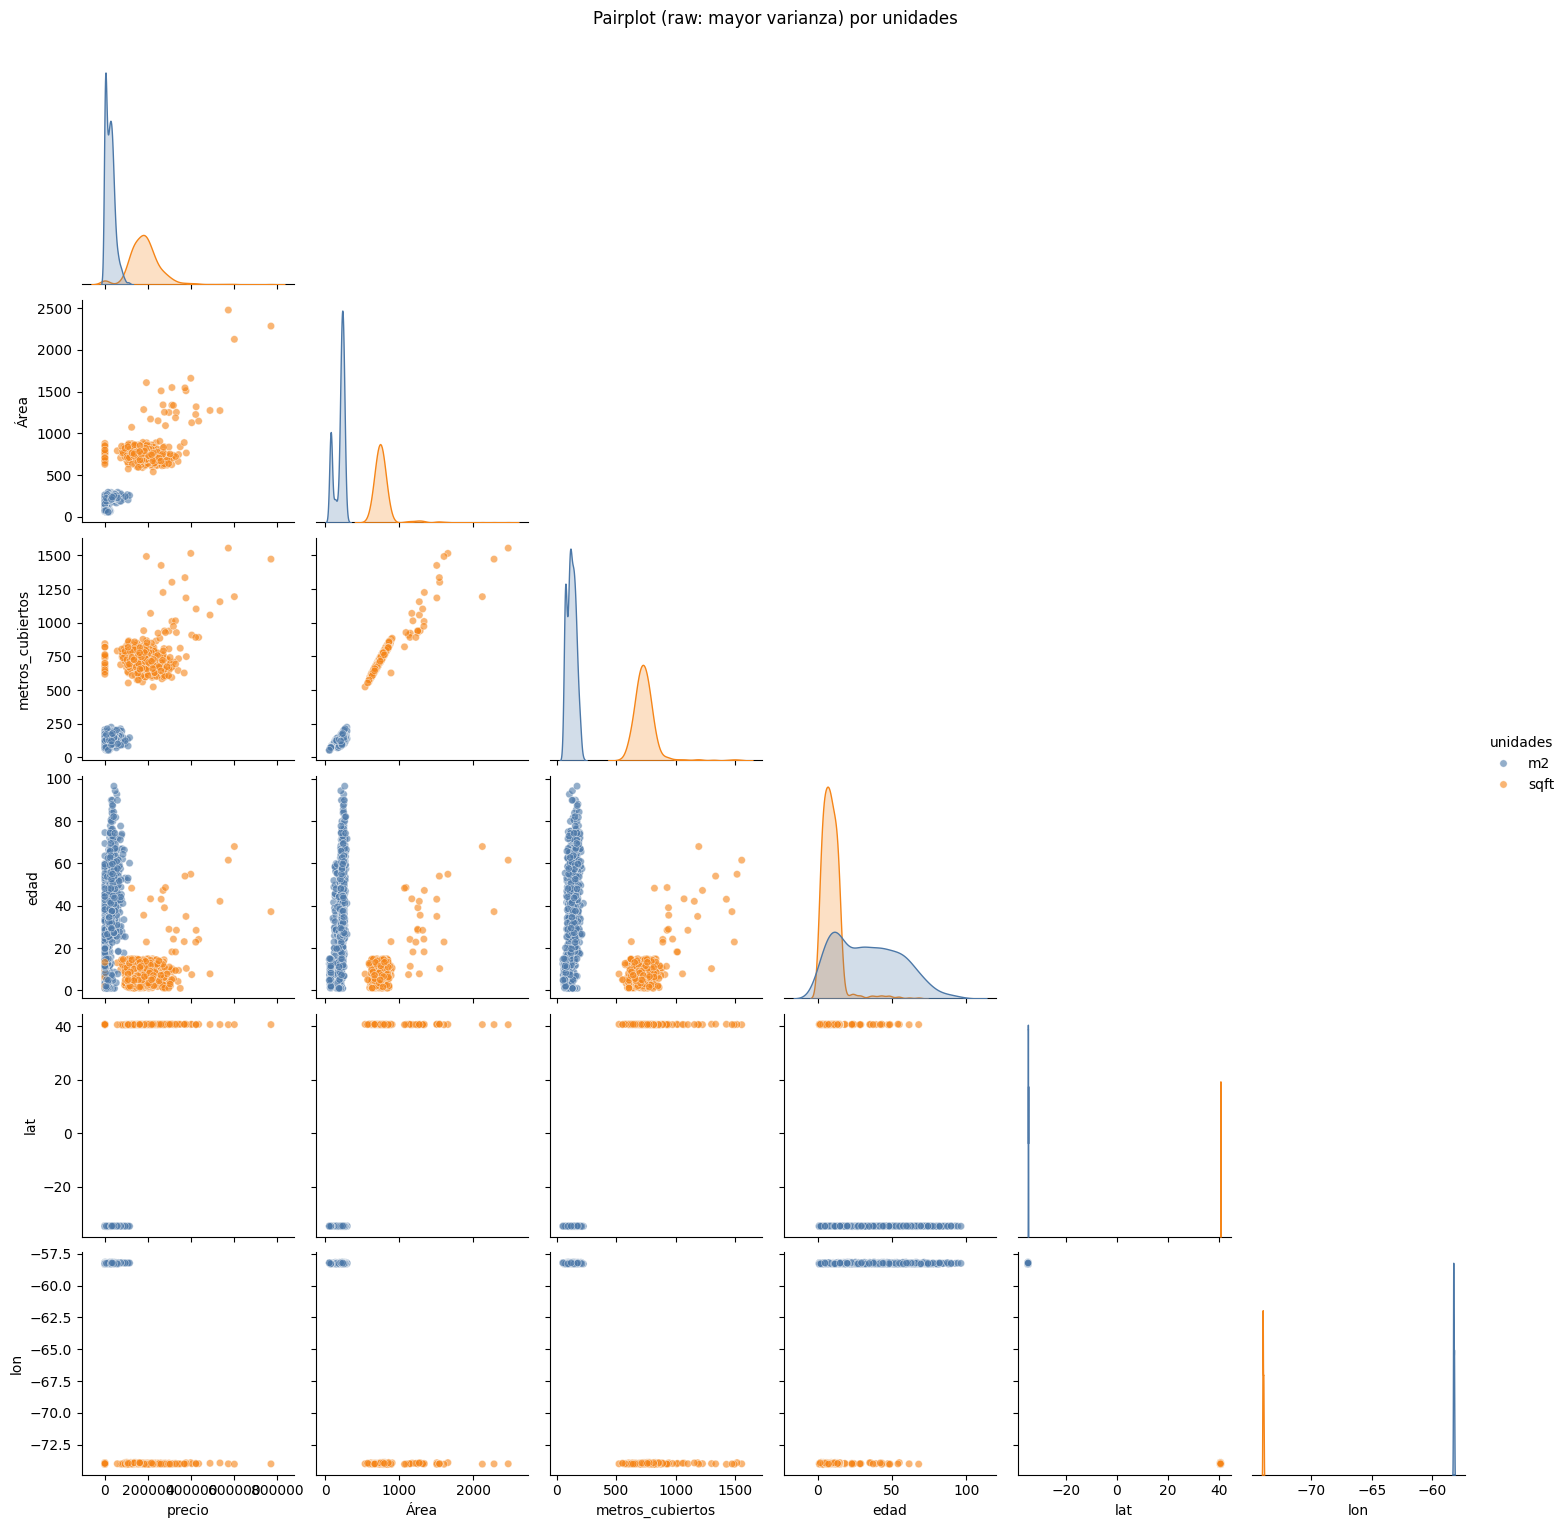

In [2]:
# 1.2 - Gráficos con datos crudos (data/raw/casas_dev.csv)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv("../data/raw/casas_dev.csv")

# Columnas numéricas
num_cols_raw = df_raw.select_dtypes(include=[np.number]).columns.tolist()
plot_df_raw = df_raw[num_cols_raw].dropna()

# Histograma(s) coloreados por unidades (m2 vs sqft si existe)
cols = num_cols_raw
n = len(cols)
cols_per_row = 3
rows = int(np.ceil(n / cols_per_row))
plt.figure(figsize=(cols_per_row * 4.5, rows * 3.5))
for i, c in enumerate(cols, 1):
    plt.subplot(rows, cols_per_row, i)
    if "unidades" in df_raw.columns:
        df_raw["unidades"] = df_raw["unidades"].astype(str).str.lower().str.strip()
        palette = {"m2": "#4C78A8", "sqft": "#F58518"}
        sns.histplot(
            data=df_raw,
            x=c,
            hue="unidades",
            bins=30,
            kde=True,
            multiple="layer",
            alpha=0.45,
            palette=palette
        )
        # Mostrar la leyenda solo en el primer subplot
        if i == 1:
            plt.legend(title="unidades", loc="upper right")
        else:
            ax = plt.gca()
            leg = ax.get_legend()
            if leg:
                leg.remove()
    else:
        sns.histplot(df_raw[c].dropna(), kde=True, bins=30, color="#4C78A8")

    plt.title(f"Histograma: {c}")
    plt.xlabel(c)
plt.tight_layout()
plt.show()

# Boxplots separados por grupos (precio, tamaños, otras)

def available(cols):
    return [c for c in cols if c in df_raw.columns]

price_col = available(["precio"])
size_cols = available(["Área", "metros_cubiertos"])
# Separar ambientes/pisos de edad
low_mag_cols = available(["ambientes", "pisos"])
age_cols = available(["edad"])

# 1) Precio
if price_col:
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    sns.boxplot(data=df_raw[price_col], orient="h", ax=ax, color="#72B7B2")
    ax.set_title("Precio (escala original)")
    ax.set_xlabel("precio")
    plt.tight_layout()
    plt.show()

# 2) Tamaños (Área y metros_cubiertos)
if size_cols:
    df_size = df_raw[size_cols].dropna()
    fig, ax = plt.subplots(1, 1, figsize=(10, 4))
    sns.boxplot(data=df_size, orient="h", ax=ax, palette="Blues")
    ax.set_title("Tamaños (Área y metros_cubiertos)")
    plt.tight_layout()
    plt.show()

# 3a) Ambientes y pisos (escala 0–11)
if low_mag_cols:
    df_low = df_raw[low_mag_cols].dropna()
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.5))
    sns.boxplot(data=df_low, orient="h", ax=ax, color="#4C78A8")
    ax.set_title("Ambientes y pisos")
    ax.set_xlabel("valor")
    ax.set_xlim(0, 11)
    plt.tight_layout()
    plt.show()

# 3b) Edad (escala 0–100)
if age_cols:
    df_age = df_raw[age_cols].dropna()
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.5))
    sns.boxplot(data=df_age, orient="h", ax=ax, color="#F58518")
    ax.set_title("Edad")
    ax.set_xlabel("años")
    ax.set_xlim(0, 100)
    plt.tight_layout()
    plt.show()

# Scatter plots contra precio (coloreados por unidades si existe)
if "precio" in df_raw.columns:
    candidates = [c for c in ["Área", "metros_cubiertos", "ambientes", "pisos", "edad"] if c in df_raw.columns]
    n = len(candidates)
    if n > 0:
        cols_per_row = 3
        rows = int(np.ceil(n / cols_per_row))
        plt.figure(figsize=(cols_per_row * 5, rows * 4))

        has_units = "unidades" in df_raw.columns
        if has_units:
            df_raw["unidades"] = df_raw["unidades"].astype(str).str.lower().str.strip()
            palette = {"m2": "#4C78A8", "sqft": "#F58518"}

        axes = []
        for i, c in enumerate(candidates, 1):
            ax = plt.subplot(rows, cols_per_row, i)
            axes.append(ax)
            if has_units:
                sns.scatterplot(
                    data=df_raw, x=c, y="precio",
                    hue="unidades", palette=palette, alpha=0.6, s=30,
                    legend=(i == 1), ax=ax
                )
                if i == 1:
                    ax.legend(title="unidades", loc="upper left", bbox_to_anchor=(1.02, 1.0))
            else:
                sns.scatterplot(data=df_raw, x=c, y="precio", alpha=0.6, s=30, ax=ax)

            ax.set_xlabel(c)
            ax.set_ylabel("precio")
            ax.set_title(f"precio vs {c}")

        plt.tight_layout()
        plt.show()

# Pairplot de columnas con mayor varianza, coloreado por unidades (m2 vs sqft)
variance = plot_df_raw.var(numeric_only=True).sort_values(ascending=False)
var_cols = variance.head(min(6, len(variance))).index.tolist()
pp_cols = [c for c in var_cols if c in df_raw.columns]

if len(pp_cols) >= 2:
    if "unidades" in df_raw.columns:
        # Normalizar etiquetas (por si hay mayúsculas/espacios)
        df_raw["unidades"] = df_raw["unidades"].astype(str).str.lower().str.strip()
        palette = {"m2": "#4C78A8", "sqft": "#F58518"}
        df_pp = df_raw.dropna(subset=pp_cols + ["unidades"]).copy()
        g = sns.pairplot(
            df_pp,
            vars=pp_cols,
            hue="unidades",
            corner=True,
            diag_kind="kde",
            plot_kws={"alpha": 0.6, "s": 28},
            palette=palette
        )
        g.fig.suptitle("Pairplot (raw: mayor varianza) por unidades", y=1.02)
        plt.show()
    else:
        print("Columna 'unidades' no encontrada; se muestra pairplot sin color.")
        g = sns.pairplot(df_raw[pp_cols].dropna(), corner=True, diag_kind="kde")
        g.fig.suptitle("Pairplot (raw: mayor varianza)", y=1.02)
        plt.show()
else:
    print("Pairplot no disponible (columnas insuficientes)")

### 1.2 - Conclusiones rápidas (datos crudos)

- Precio, Área y metros_cubiertos muestran sesgo a la derecha y outliers altos;
- Al colorear por unidades, m2 y sqft quedan bien diferenciados y operan en escalas distintas;
- Scatter precio vs Área/metros_cubiertos: relación positiva clara; metros_cubiertos parece asociarse levemente mejor con precio.
- Ambientes crece con el tamaño y se relaciona de forma moderada con precio; pisos muestra efecto débil; edad sugiere leve relación negativa con precio.
- El pairplot confirma alta correlación entre Área y metros_cubiertos y correlación moderada con precio; el resto de numéricas aportan menos señal directa.
- Se observan dos grupos geográficos (lat/lon) con patrones distintos (p. ej., NYC vs AMBA), potencial fuente de heterogeneidad.
- Hay faltantes y algunos valores atípicos (p. ej., precio ≤ 0); deberán tratarse en

In [3]:
#1.3
import pandas as pd
import sys
sys.path.append('../src')
from preprocessing import handle_missing_values, one_hot_encode, normalize, train_test_split

#le aplico las correcciones a casas_dev.csv y a casas_test.csv
# 1. Cargar los datos
df_dev = pd.read_csv("../data/raw/casas_dev.csv")
df_test = pd.read_csv("../data/raw/casas_test.csv")

# 2. Aplicar las funciones de preprocesamiento
df_dev = handle_missing_values(df_dev)
df_test = handle_missing_values(df_test)

#one_hot_encode tipo
df_dev = one_hot_encode(df_dev, 'tipo')
df_test = one_hot_encode(df_test, 'tipo')

# Normalizar los datos, Área, metros_cubiertos, ambientes, edad, pisos
df_dev = normalize(df_dev, ['Área', 'metros_cubiertos', 'ambientes', 'edad', 'pisos'])
df_test = normalize(df_test, ['Área', 'metros_cubiertos', 'ambientes', 'edad', 'pisos'])

# 3. Guardar los archivos procesados
df_dev.to_csv("../data/processed/casas_dev.csv", index=False)
df_test.to_csv("../data/processed/casas_test.csv", index=False)

# 4. separar dataset en training y validation 80/20
df_train, df_val = train_test_split(df_dev, test_size=0.2, random_state=42)

df_train.to_csv("../data/processed/casas_train.csv", index=False)
df_val.to_csv("../data/processed/casas_val.csv", index=False)
